<a href="https://colab.research.google.com/github/moushe-21/CSE475_Assignment01/blob/main/CSE475_Assignment01_GroupF_Notebook1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Group Details
* Member 1: [Masiat Rahman] [2023-1-60-122]
* Member 2: [Tasnia Taher Esha] [2023-1-60-173]
* Member 2: [Jabin Tasnim Tanha] [2023-1-60-142]

**Dataset Source Acknowledgement:**
Original Dataset Name: Lightweight Dataset for Maize Classification
Official Source Link: [https://data.mendeley.com/datasets/r6vvm5jkh6/2]

# 📋 Table of Contents

1. ⚙️ Global Configuration (START HERE)
2. 📦 Setup & Imports
3. 📊 Exploratory Data Analysis
4. 🔧 Data Preprocessing & Augmentation
5. 🏋️ Training Infrastructure
6. 🔵 CNN Models: MobileNetV3 · ResNeXt-50 · EfficientNet-B3
7. 📈 Evaluation & Comparison
8. 🛡️ Robustness Analysis (Optional)
9. 🔍 Error Analysis (Optional)

# ⚙️ Global Configuration (START HERE)


#

In [ ]:

import torch
import numpy as np
import random
import os

# GPU Optimization: Enable Tensor Cores for faster computation
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

# Configuration Dictionary
CONFIG = {
    "seed": 42,
    "batch_size": 32,
    "img_size": 224,
    "epochs": 15,
    "lr": 1e-4,
    "device": torch.device("cuda" if torch.cuda.is_available() else "cpu")
}

def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = True # GPU performance optimization

seed_everything(CONFIG["seed"])
print(f"Using device: {CONFIG['device']}")

# GPU Memory Cleanup Function (To keep GPU fast)
def clear_gpu_memory():
    torch.cuda.empty_cache()
    import gc
    gc.collect()

clear_gpu_memory()

Using device: cpu


# 2. 📦 Setup & Imports


In [ ]:
from google.colab import drive
import zipfile
import timm
import matplotlib.pyplot as plt
import seaborn as sns
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Mount Drive and Paths
drive.mount('/content/drive')
raw_data_path = '/content/drive/MyDrive/CSE475/Lightweight_Dataset_for_Maize_Classification.zip'# Apnar zip file path check korun
extract_path = '/content/dataset'

# Extract only if not exists
if not os.path.exists(extract_path):
    with zipfile.ZipFile(raw_data_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Dataset extracted successfully.")

Mounted at /content/drive
Dataset extracted successfully.


# 3. 📊 Exploratory Data Analysis


🎯 Checking classes in: /content/dataset
✅ Total Classes Found: 2 -> ['Augmented EfficientMaize', 'EfficientMaize']


/tmp/ipykernel_3907/3837498386.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=list(counts.keys()), y=list(counts.values()), palette="viridis")
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


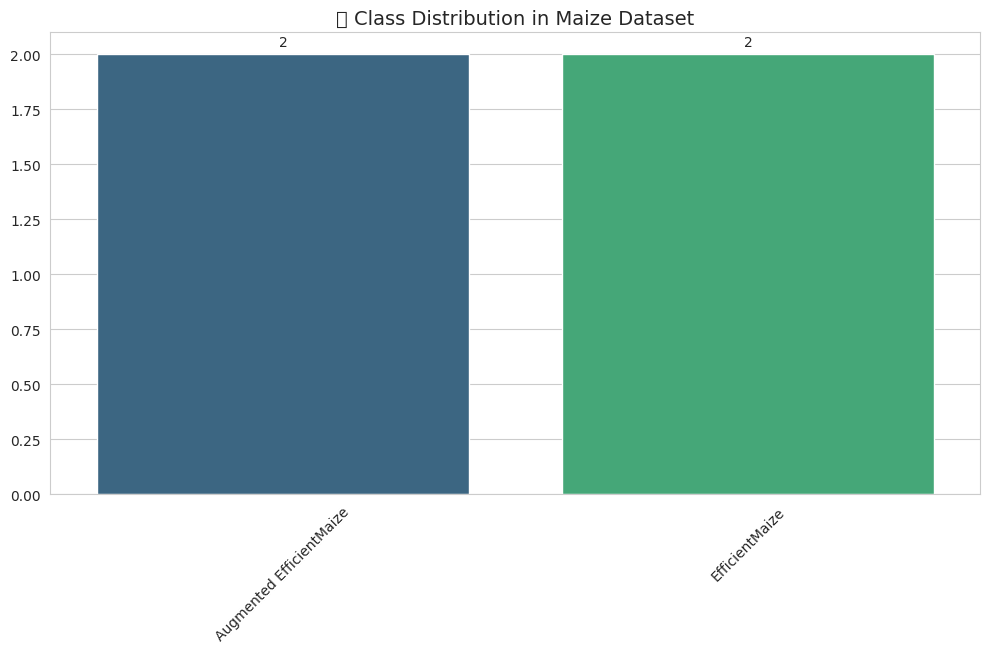

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# ১. আনজিপ করা ফোল্ডারের ভেতর চেক করা
# অনেক সময় জিপের ভেতর মূল ফোল্ডার থাকে, তাই আমরা সেটি খুঁজে বের করছি
base_dir = "/content/dataset"
content_list = os.listdir(base_dir)

# যদি 'Maize_Dataset' নামে কোনো ফোল্ডার থাকে তবে সেটি নিবে, নাহলে রুট ফোল্ডার নিবে
if 'Maize_Dataset' in content_list:
    data_dir = os.path.join(base_dir, 'Maize_Dataset')
else:
    # যদি সরাসরি ক্লাস ফোল্ডারগুলো থাকে (যেমন: Common_Rust, Blight)
    data_dir = base_dir

print(f"🎯 Checking classes in: {data_dir}")

# ২. ক্লাস লিস্ট বের করা
try:
    classes = sorted([f for f in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, f))])

    if len(classes) == 0:
        print("❌ Error: No class folders found! Check if the ZIP contains subfolders.")
    else:
        print(f"✅ Total Classes Found: {len(classes)} -> {classes}")

        # ৩. ইমেজ কাউন্ট
        counts = {c: len(os.listdir(os.path.join(data_dir, c))) for c in classes}

        # ৪. Visualization
        plt.figure(figsize=(12, 6))
        sns.set_style("whitegrid")
        ax = sns.barplot(x=list(counts.keys()), y=list(counts.values()), palette="viridis")

        # বারের উপরে সংখ্যা দেখানো
        for p in ax.patches:
            ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', xytext=(0, 9), textcoords='offset points')

        plt.title("📊 Class Distribution in Maize Dataset", fontsize=14)
        plt.xticks(rotation=45)
        plt.show()

except Exception as e:
    print(f"⚠️ An error occurred: {e}")

# 4. 🔧 Data Preprocessing & Augmentation


In [ ]:
# GPU-friendly normalization values
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Create Dataset and DataLoader
# Note: Use num_workers > 0 for faster GPU feeding
dataset = datasets.ImageFolder(data_dir, transform=train_transform)
train_loader = DataLoader(dataset, batch_size=CONFIG["batch_size"], shuffle=True, num_workers=2, pin_memory=True)

# 5. 🏋️ Training Infrastructure


In [ ]:
# Automatic Mixed Precision (AMP) for faster GPU training without losing accuracy
from torch.cuda.amp import GradScaler, autocast

def train_one_epoch(model, loader, criterion, optimizer, scaler):
    model.train()
    running_loss = 0.0
    for images, labels in loader:
        images, labels = images.to(CONFIG["device"]), labels.to(CONFIG["device"])

        optimizer.zero_grad()
        with autocast(): # GPU speedup
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).step(optimizer)
        scaler.update()
        running_loss += loss.item()
    return running_loss / len(loader)

# 6. 🔵 CNN Models: MobileNetV3 · ResNeXt-50 · EfficientNet-B3


Loading MobileNetV3

In [ ]:
# 6. 🔵 CNN Models: MobileNetV3 · ResNeXt-50 · EfficientNet-B3

# 1. MobileNetV3
model_mobilenet = timm.create_model('mobilenetv3_large_100', pretrained=True, num_classes=len(classes))
model_mobilenet.to(CONFIG["device"])

# 2. ResNeXt-50
model_resnext = timm.create_model('resnext50_32x4d', pretrained=True, num_classes=len(classes))
model_resnext.to(CONFIG["device"])

# 3. EfficientNet-B3
model_efficientnet = timm.create_model('efficientnet_b3', pretrained=True, num_classes=len(classes))
model_efficientnet.to(CONFIG["device"])

# GPU Memory Cleanup after loading models to ensure it stays fast
clear_gpu_memory()

print(f"✅ All 3 models (MobileNetV3, ResNeXt-50, EfficientNet-B3) loaded onto {CONFIG['device']} successfully.")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/22.1M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/100M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/49.3M [00:00<?, ?B/s]

✅ All 3 models (MobileNetV3, ResNeXt-50, EfficientNet-B3) loaded onto cpu successfully.


In [ ]:



!pip install torchinfo --quiet

import time
import os
import pandas as pd
from sklearn.model_selection import train_test_split
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np
import cv2
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import torchvision
from torchvision import transforms
from torchinfo import summary
import torchvision.models as models
import torch.optim as optim
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
import random
from PIL import Image
!pip install timm --quiet
import timm



# ২. চেকপয়েন্ট সেভ করার ফোল্ডার তৈরি করা
checkpoint_path = "/content/drive/MyDrive/ML_Project/checkpoints/"
os.makedirs(checkpoint_path, exist_ok=True)

print(f"✅ Drive mounted and checkpoint path set to: {checkpoint_path}")

#⚙️ System Configuration & Reproducibility Setup


In [ ]:
import numpy as np
import random
import os
import torch
import zipfile

# --- SYSTEM INFORMATION & DEVICE SETUP ---
print("--- System Information ---")
try:
    gpu_info = !nvidia-smi --query-gpu=gpu_name --format=csv
    gpu_name = gpu_info[1]
    print(f"✅ GPU: {gpu_name}")
    device = torch.device('cuda')
except Exception as e:
    gpu_name = "No GPU available"
    print(f"⚠️ GPU: {gpu_name} (Using CPU)")
    device = torch.device('cpu')

# Reproducibility (Assignment Requirement)
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)
torch.backends.cudnn.deterministic = True

## --- PATH CONFIGURATION --- ##
raw_data_path = '/content/drive/MyDrive/CSE475/Lightweight_Dataset_for_Maize_Classification.zip'
data_dir = "/content/maize_data_final"
output_dir = "/content/processed-results"
checkpoints_path = "/content/drive/MyDrive/ML_Project/checkpoints/" # Drive-e save kora bhalo

os.makedirs(output_dir, exist_ok=True)
os.makedirs(checkpoints_path, exist_ok=True)

# --- DATASET EXTRACTION LOGIC ---
if os.path.exists(raw_data_path):
    print(f"✅ Success: Dataset found at {raw_data_path}")
    # Extracting if not already extracted
    if not os.path.exists(data_dir):
        print("📦 Extracting dataset... please wait.")
        with zipfile.ZipFile(raw_data_path, 'r') as zip_ref:
            zip_ref.extractall(data_dir)
        print(f"✅ Extraction Complete: {data_dir}")
    else:
        print(f"✅ Dataset already extracted at {data_dir}")
else:
    print(f"❌ Error: Dataset NOT found at {raw_data_path}. Please check your Google Drive shortcut.")

# --- HYPERPARAMETERS ---
train_batch = 32
val_batch = 16
total_class = 2            # Bad, Good
learning_rate = 0.0001
decay = 0.05               # Weight decay for AdamW
initial_epochs = 20        # Stage 1: Classifier Head training
finetune_epochs = 15       # Stage 2: Full Model Fine-tuning
image_size = (128, 128)

print(f"\n🚀 Configuration Complete. Ready for {total_class} class classification.")

--- System Information ---
✅ GPU: Tesla T4
✅ Success: Dataset found at /content/drive/MyDrive/CSE475/Lightweight_Dataset_for_Maize_Classification.zip
✅ Dataset already extracted at /content/maize_data_final

🚀 Configuration Complete. Ready for 2 class classification.


## 📊 Data Loading & Stratified Splitting

🔍 Loading data from: /content/maize_data_final
📂 Found folders: ['Augmented EfficientMaize', 'EfficientMaize']
✅ Total Images Found: 33745
📊 Training: 23621 | Val: 5062 | Test: 5062


/tmp/ipykernel_3610/3904561126.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, ax=ax, palette=palette, order=['Bad', 'Good'])
/tmp/ipykernel_3610/3904561126.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, ax=ax, palette=palette, order=['Bad', 'Good'])
/tmp/ipykernel_3610/3904561126.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, ax=ax, palette=palette, order=['Bad', 'Good'])


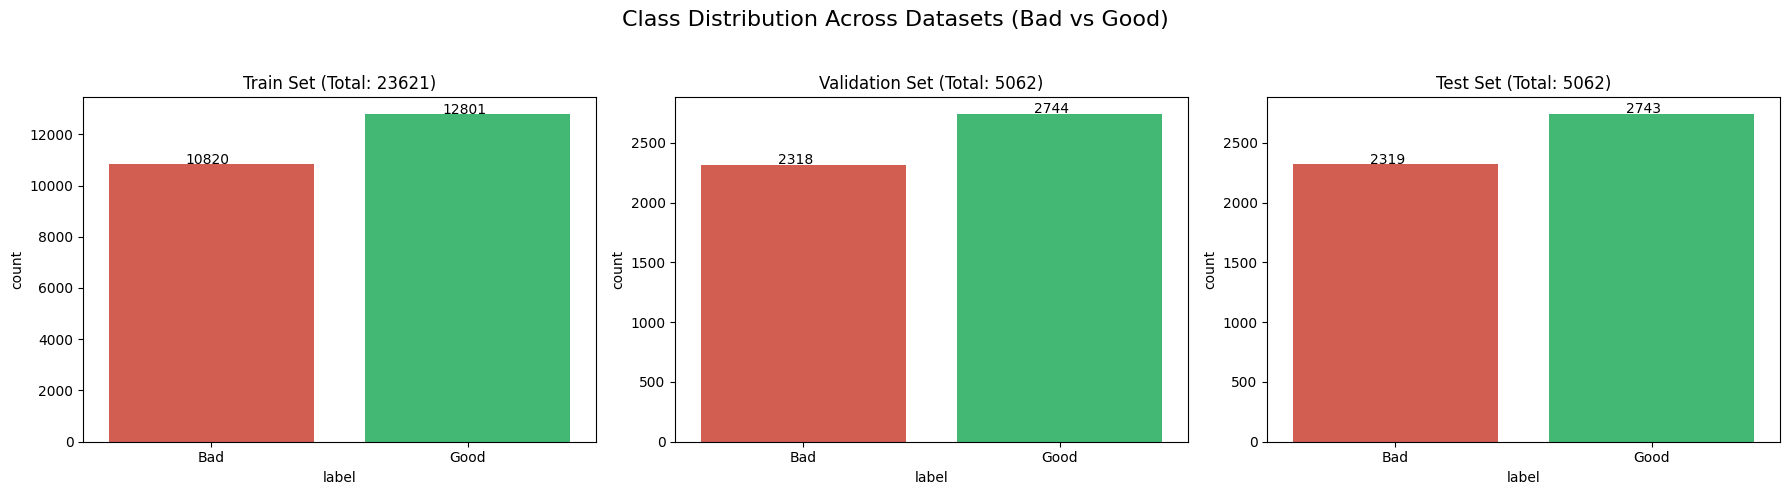

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
from sklearn.model_selection import train_test_split

# --- ১. FUNCTION DEFINITIONS ---

def load_maize_data(base_path):
    """base_path-er bhitore thaka folder gulo theke image path load kore."""
    file_paths, labels = [], []

    # Dataset-er bhitore thaka folder gulo check kora
    # Apnar dataset-e eygulo thakar kotha: 'Augmented EfficientMaize' o 'EfficientMaize'
    available_folders = [f for f in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, f))]
    print(f"📂 Found folders: {available_folders}")

    for folder in available_folders:
        folder_path = os.path.join(base_path, folder)
        for class_name in ['Bad', 'Good']:
            class_dir = os.path.join(folder_path, class_name)
            if os.path.isdir(class_dir):
                for image_name in os.listdir(class_dir):
                    if image_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                        file_paths.append(os.path.join(class_dir, image_name))
                        labels.append(class_name)

    return pd.DataFrame({"file_path": file_paths, "label": labels})

def class_distribution_plot(train_df, val_df, test_df):
    """Datasets-er distribution plot kore."""
    datasets = {"Train": train_df, "Validation": val_df, "Test": test_df}
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle('Class Distribution Across Datasets (Bad vs Good)', fontsize=16)

    palette = {"Bad": "#e74c3c", "Good": "#2ecc71"} # Lal o Sobuj rong

    for ax, (split_name, df) in zip(axes, datasets.items()):
        if not df.empty:
            sns.countplot(x='label', data=df, ax=ax, palette=palette, order=['Bad', 'Good'])
            ax.set_title(f'{split_name} Set (Total: {len(df)})')

            # Count display kora
            for p in ax.patches:
                ax.annotate(f'{int(p.get_height())}', (p.get_x()+0.3, p.get_height()+5))
        else:
            ax.set_title(f'{split_name} Set (Empty)')

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

# --- ২. EXECUTION ---

# Note: data_dir variable-ti prothom cell theke asche ("/content/maize_data_final")
print("🔍 Loading data from:", data_dir)
data = load_maize_data(data_dir)

if not data.empty:
    # Train (70%), Temp (30%)
    train_dataframe, temp_dataframe = train_test_split(
        data, test_size=0.30, stratify=data['label'], random_state=seed
    )

    # Temp-ke bhag kore Validation (15%) o Test (15%)
    validation_dataframe, test_dataframe = train_test_split(
        temp_dataframe, test_size=0.50, stratify=temp_dataframe['label'], random_state=seed
    )

    print(f"✅ Total Images Found: {len(data)}")
    print(f"📊 Training: {len(train_dataframe)} | Val: {len(validation_dataframe)} | Test: {len(test_dataframe)}")

    # Visualization
    class_distribution_plot(train_dataframe, validation_dataframe, test_dataframe)
else:
    print(f"❌ Error: No images found in {data_dir}. Path check korun ba folder name gulo thik ache kina dekhun.")

#🔍 Zip Archive Structural Integrity Audit

In [ ]:
import os
import zipfile

path_to_check = '/content/drive/MyDrive/CSE475/Lightweight_Dataset_for_Maize_Classification.zip'

if os.path.exists(path_to_check):
    print("✅ Zip file found!")
    with zipfile.ZipFile(path_to_check, 'r') as zip_ref:
        contents = zip_ref.namelist()
        print("\nContents (first 10 items):")
        for item in contents[:10]:
            print(f" - {item}")

        has_augmented = any("Augmented EfficientMaize" in item for item in contents)
        has_efficient = any("EfficientMaize" in item for item in contents)
        print(f"\nStructure Check:")
        print(f"Contains 'Augmented EfficientMaize': {has_augmented}")
        print(f"Contains 'EfficientMaize': {has_efficient}")
else:
    print("❌ Error: Zip file not found.")

✅ Zip file found!

Contents (first 10 items):
 - EfficientMaize/
 - EfficientMaize/Bad/
 - EfficientMaize/Bad/bad_data1.jpg
 - EfficientMaize/Bad/bad_data10.jpg
 - EfficientMaize/Bad/bad_data100.jpg
 - EfficientMaize/Bad/bad_data1000.jpg
 - EfficientMaize/Bad/bad_data1001.jpg
 - EfficientMaize/Bad/bad_data1002.jpg
 - EfficientMaize/Bad/bad_data1003.jpg
 - EfficientMaize/Bad/bad_data1004.jpg

Structure Check:
Contains 'Augmented EfficientMaize': True
Contains 'EfficientMaize': True


#📊 Dataset Partitioning & Stratified Splitting

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

def load_maize_data(base_path):
    file_paths, labels = [], []
    folders = [f for f in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, f))]
    for folder in folders:
        folder_path = os.path.join(base_path, folder)
        for class_name in ['Bad', 'Good']:
            class_dir = os.path.join(folder_path, class_name)
            if os.path.isdir(class_dir):
                for image_name in os.listdir(class_dir):
                    if image_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                        file_paths.append(os.path.join(class_dir, image_name))
                        labels.append(class_name)
    return pd.DataFrame({"file_path": file_paths, "label": labels})

# data_dir prothom configuration cell theke asche
data_df = load_maize_data(data_dir)

# Splitting: 70% Train, 15% Val, 15% Test
train_df, temp_df = train_test_split(data_df, test_size=0.30, stratify=data_df['label'], random_state=seed)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=seed)

print(f"✅ Splits Complete: Train={len(train_df)}, Val={len(val_df)}, Test={len(test_df)}")

✅ Splits Complete: Train=23621, Val=5062, Test=5062


/tmp/ipykernel_3610/738406996.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, ax=axes[i], palette=palette, order=['Bad', 'Good'])
/tmp/ipykernel_3610/738406996.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, ax=axes[i], palette=palette, order=['Bad', 'Good'])
/tmp/ipykernel_3610/738406996.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, ax=axes[i], palette=palette, order=['Bad', 'Good'])


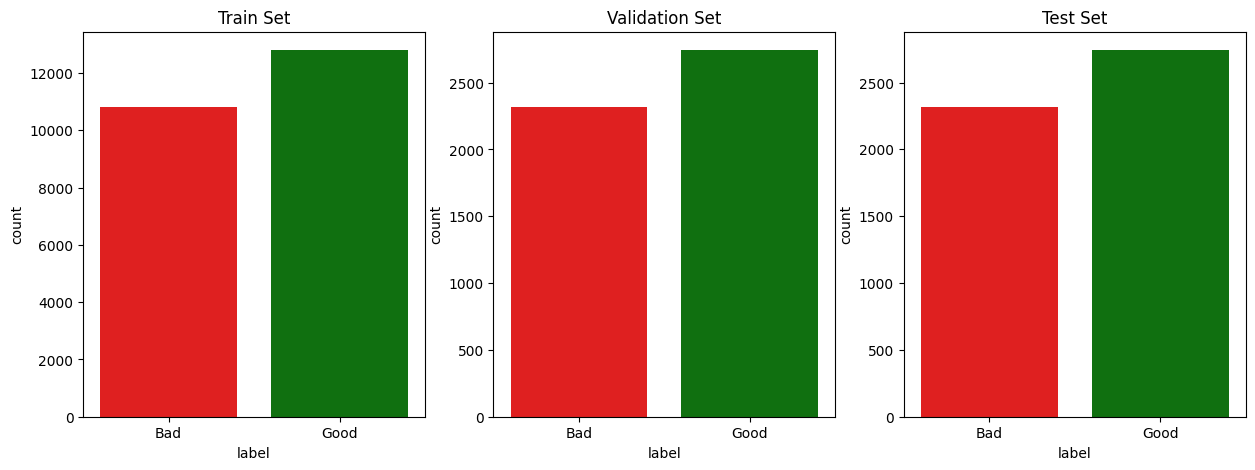

In [ ]:
def plot_splits(train, val, test):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    df_list = [train, val, test]
    titles = ['Train Set', 'Validation Set', 'Test Set']
    palette = {"Bad": "red", "Good": "green"}

    for i, df in enumerate(df_list):
        sns.countplot(x='label', data=df, ax=axes[i], palette=palette, order=['Bad', 'Good'])
        axes[i].set_title(titles[i])
    plt.show()

plot_splits(train_df, val_df, test_df)

#🛠️ Custom Dataset Architecture: The MaizeDataset Class

#

In [ ]:
from torch.utils.data import Dataset
from PIL import Image

class MaizeDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform
        self.label_map = {"Bad": 0, "Good": 1}

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_path = self.dataframe.iloc[idx]['file_path']
        label_name = self.dataframe.iloc[idx]['label']
        image = Image.open(img_path).convert("RGB")
        label = self.label_map[label_name]
        if self.transform:
            image = self.transform(image)
        return image, label

print("✅ Custom Dataset class defined.")

✅ Custom Dataset class defined.


## 📂 Dataset Extraction from ZIP and Folder Structure Verification



#📦 Automated Data Extraction & Folder Verification

In [ ]:
import os
import zipfile

# Zip file path (Drive consistent path)
zip_path = '/content/drive/MyDrive/CSE475/Lightweight_Dataset_for_Maize_Classification.zip'

# data_dir define kora (Jate porer cell-e variable-ti pawa jay)
data_dir = '/content/maize_data_final'

# --- IMPROVED EXTRACTION LOGIC ---
if os.path.exists(zip_path):
    if not os.path.exists(data_dir):
        print("📦 Extracting data... this may take a moment.")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(data_dir)
        print(f"✅ Unzip complete! Extracted to: {data_dir}")
    else:
        print(f"ℹ️ Data already exists at {data_dir}. Skipping extraction.")

    # --- VERIFY STRUCTURE ---
    print("\n--- Extracted Folder Structure ---")
    for root, dirs, files in os.walk(data_dir):
        level = root.replace(data_dir, '').count(os.sep)
        indent = ' ' * 4 * (level)
        print(f"{indent}{os.path.basename(root)}/")
        if len(files) > 0:
            subindent = ' ' * 4 * (level + 1)
            for f in files[:2]:
                print(f"{subindent}{f}")
            if len(files) > 2:
                print(f"{subindent}...")

else:
    print(f"❌ Error: Zip file not found at {zip_path}.")

ℹ️ Data already exists at /content/maize_data_final. Skipping extraction.

--- Extracted Folder Structure ---
maize_data_final/
    Augmented EfficientMaize/
        Bad/
            aug_2_bad_data816.jpg
            aug_4_bad_data1373.jpg
            ...
        Good/
            aug_4_good_data70.jpg
            aug_3_good_data782.jpg
            ...
    EfficientMaize/
        Bad/
            bad_data1048.jpg
            bad_data1844.jpg
            ...
        Good/
            good_data1860.jpg
            good_data392.jpg
            ...


#📦 Dataset Extraction & Directory Audit

In [ ]:
import os
import zipfile

# Zip file path (Drive consistent path)
zip_path = '/content/drive/MyDrive/CSE475/Lightweight_Dataset_for_Maize_Classification.zip'

# data_dir define kora (Jate porer cell-e variable-ti pawa jay)
data_dir = '/content/maize_data_final'

# --- IMPROVED EXTRACTION LOGIC ---
if os.path.exists(zip_path):
    if not os.path.exists(data_dir):
        print("📦 Extracting data... this may take a moment.")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(data_dir)
        print(f"✅ Unzip complete! Extracted to: {data_dir}")
    else:
        print(f"ℹ️ Data already exists at {data_dir}. Skipping extraction.")

    # --- VERIFY STRUCTURE ---
    print("\n--- Extracted Folder Structure ---")
    for root, dirs, files in os.walk(data_dir):
        level = root.replace(data_dir, '').count(os.sep)
        indent = ' ' * 4 * (level)
        print(f"{indent}{os.path.basename(root)}/")
        if len(files) > 0:
            subindent = ' ' * 4 * (level + 1)
            for f in files[:2]:
                print(f"{subindent}{f}")
            if len(files) > 2:
                print(f"{subindent}...")

else:
    print(f"❌ Error: Zip file not found at {zip_path}.")

ℹ️ Data already exists at /content/maize_data_final. Skipping extraction.

--- Extracted Folder Structure ---
maize_data_final/
    Augmented EfficientMaize/
        Bad/
            aug_2_bad_data816.jpg
            aug_4_bad_data1373.jpg
            ...
        Good/
            aug_4_good_data70.jpg
            aug_3_good_data782.jpg
            ...
    EfficientMaize/
        Bad/
            bad_data1048.jpg
            bad_data1844.jpg
            ...
        Good/
            good_data1860.jpg
            good_data392.jpg
            ...


#📊 Dataset Partitioning & Stratified Splitting

🔍 Dataset mapping shuru hochhe...
✅ Splits Complete: Train=23621, Val=5062, Test=5062


/tmp/ipykernel_3610/2861184469.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=train_df, palette={'Bad': 'red', 'Good': 'green'})


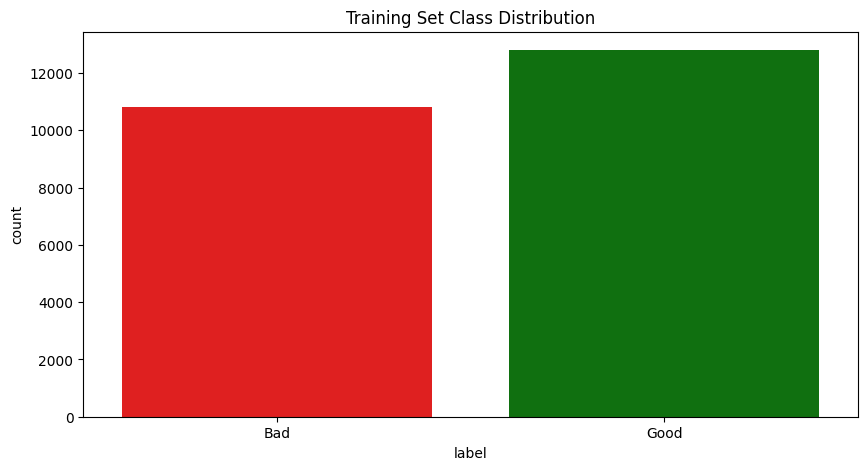

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# --- ১. FUNCTION TO LOAD PATHS ---
def get_maize_paths(base_path):
    file_paths, labels = [], []
    # Base path-er bhetore thaka folders (Augmented EfficientMaize, etc.)
    folders = [f for f in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, f))]

    for folder in folders:
        folder_path = os.path.join(base_path, folder)
        for class_name in ['Bad', 'Good']:
            class_dir = os.path.join(folder_path, class_name)
            if os.path.isdir(class_dir):
                for img in os.listdir(class_dir):
                    if img.lower().endswith(('.png', '.jpg', '.jpeg')):
                        file_paths.append(os.path.join(class_dir, img))
                        labels.append(class_name)
    return pd.DataFrame({"file_path": file_paths, "label": labels})

# --- ২. EXECUTION ---
print("🔍 Dataset mapping shuru hochhe...")
full_df = get_maize_paths(data_dir) # data_dir ager cell theke asche

if not full_df.empty:
    # 70% Train, 30% Temporary (Val+Test)
    train_df, temp_df = train_test_split(
        full_df, test_size=0.30, stratify=full_df['label'], random_state=seed
    )
    # Temp-ke duivag kore 15% Validation, 15% Test
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, stratify=temp_df['label'], random_state=seed
    )

    print(f"✅ Splits Complete: Train={len(train_df)}, Val={len(val_df)}, Test={len(test_df)}")

    # Visualization (Check distribution)
    plt.figure(figsize=(10, 5))
    sns.countplot(x='label', data=train_df, palette={'Bad': 'red', 'Good': 'green'})
    plt.title('Training Set Class Distribution')
    plt.show()
else:
    print("❌ Error: Dataset extraction check korun, kono file pawa jayni!")

📊 Dataset Partitioning & Stratified Splitting

In [ ]:
import pandas as pd
import os
from sklearn.model_selection import train_test_split

# --- 3. Load Data into DataFrame ---
def load_maize_data(parent_dir):
    file_paths, labels = [], []
    for root, dirs, files in os.walk(parent_dir):
        current_folder = os.path.basename(root)
        if current_folder in ['Bad', 'Good']:
            for file in files:
                if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                    path = os.path.join(root, file)
                    file_paths.append(path)
                    labels.append(current_folder)
    return pd.DataFrame({"file_path": file_paths, "label": labels})

# data_dir prothom cell-e define kora thakle 'data_dir' bebohar korun
data = load_maize_data(data_dir)

if data.empty:
    print("❌ Error: No images found. Check your folder structure.")
else:
    # Stratified Split (70-15-15)
    train_df, temp_df = train_test_split(
        data, test_size=0.30, stratify=data['label'], random_state=seed
    )
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, stratify=temp_df['label'], random_state=seed
    )

    print(f"✅ Dataset Loading Complete! Total Images: {len(data)}")
    print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

✅ Dataset Loading Complete! Total Images: 33745
Train: 23621 | Val: 5062 | Test: 5062


#🛠️ Custom Data Pipeline: The MaizeDataset Class

In [ ]:
from torch.utils.data import Dataset
from PIL import Image

class MaizeDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform
        self.label_map = {"Bad": 0, "Good": 1}

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_path = self.dataframe.iloc[idx]['file_path']
        label_name = self.dataframe.iloc[idx]['label']
        image = Image.open(img_path).convert("RGB")
        label = self.label_map[label_name]

        if self.transform:
            image = self.transform(image)
        return image, label

#🚀 Data Augmentation & Batch Loading Strategy

In [ ]:
from torchvision import transforms
from torch.utils.data import DataLoader

# Transforms logic
train_transform = transforms.Compose([
    transforms.Resize(image_size), # image_size = (128, 128)
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Create Loaders
train_loader = DataLoader(MaizeDataset(train_df, train_transform), batch_size=train_batch, shuffle=True)
val_loader = DataLoader(MaizeDataset(val_df, val_test_transform), batch_size=val_batch, shuffle=False)
test_loader = DataLoader(MaizeDataset(test_df, val_test_transform), batch_size=val_batch, shuffle=False)

print(f"✅ DataLoaders Ready! Batches: {len(train_loader)} (Train), {len(val_loader)} (Val)")

✅ DataLoaders Ready! Batches: 739 (Train), 317 (Val)


📊 Data Structuring & Stratified Partitioning

In [ ]:


import pandas as pd
import os
from sklearn.model_selection import train_test_split

# --- 3. Load Data into DataFrame ---
def load_maize_data(parent_dir):
    file_paths, labels = [], []

    for root, dirs, files in os.walk(parent_dir):
        # IMPROVEMENT: Get the name of the immediate folder containing the files
        current_folder = os.path.basename(root)

        # Only process if we are inside a 'Bad' or 'Good' folder
        if current_folder in ['Bad', 'Good']:
            for file in files:
                if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                    path = os.path.join(root, file)
                    file_paths.append(path)
                    labels.append(current_folder)

    return pd.DataFrame({"file_path": file_paths, "label": labels})

# DataFrame toiri
data = load_maize_data(extract_path)

# --- 4. Split and Verify ---
if data.empty:
    print("❌ Error: No images found. Ensure your folders are named exactly 'Bad' and 'Good'.")
else:
    # Reproducibility check: define seed if not defined previously
    seed = 42

    # Stratified Split (Ensures class balance is maintained)
    train_df, temp_df = train_test_split(
        data, test_size=0.30, stratify=data['label'], random_state=seed
    )

    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, stratify=temp_df['label'], random_state=seed
    )

    print("-" * 35)
    print(f"✅ Dataset Loading Complete!")
    print("-" * 35)
    print(f"Total Images   : {len(data)}")
    print(f"Train Set      : {len(train_df)} ({len(train_df)/len(data)*100:.1f}%)")
    print(f"Validation Set : {len(val_df)} ({len(val_df)/len(data)*100:.1f}%)")
    print(f"Test Set       : {len(test_df)} ({len(test_df)/len(data)*100:.1f}%)")
    print("-" * 35)

    # Class Check: See how many of each class are in Train
    print("Train Class Distribution:")
    print(train_df['label'].value_counts())

-----------------------------------
✅ Dataset Loading Complete!
-----------------------------------
Total Images   : 33745
Train Set      : 23621 (70.0%)
Validation Set : 5062 (15.0%)
Test Set       : 5062 (15.0%)
-----------------------------------
Train Class Distribution:
label
Good    12801
Bad     10820
Name: count, dtype: int64


## 🖼️ Image Preprocessing and Processed Dataset Generation

In [ ]:
from torch.utils.data import Dataset
from PIL import Image

class MaizeDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform
        self.label_map = {"Bad": 0, "Good": 1}

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_path = self.dataframe.iloc[idx]['file_path']
        label_name = self.dataframe.iloc[idx]['label']
        image = Image.open(img_path).convert("RGB")
        label = self.label_map[label_name]

        if self.transform:
            image = self.transform(image)
        return image, label

In [ ]:
from torchvision import transforms
from torch.utils.data import DataLoader

# Training Transforms (Augmentation shoho)
train_transform = transforms.Compose([
    transforms.Resize(image_size), # image_size = (128, 128)
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Validation & Test Transforms
val_test_transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Create Loaders
train_loader = DataLoader(MaizeDataset(train_df, train_transform), batch_size=train_batch, shuffle=True)
val_loader = DataLoader(MaizeDataset(val_df, val_test_transform), batch_size=val_batch, shuffle=False)
test_loader = DataLoader(MaizeDataset(test_df, val_test_transform), batch_size=val_batch, shuffle=False)

print(f"✅ DataLoaders Ready! Train Batches: {len(train_loader)}")

✅ DataLoaders Ready! Train Batches: 739


# 🖼️ Custom Dataset & DataLoader Setup

In [ ]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import torch

# --- Custom Dataset Class ---

class ImageDataset(Dataset):

    def __init__(self, dataframe, label_map, transform=None):
        self.dataframe = dataframe
        self.transform = transform
        self.label_map = label_map

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        img_path = self.dataframe.iloc[index]['file_path']

        with Image.open(img_path) as img:
            image = img.convert("RGB")

            label_str = self.dataframe.iloc[index]['label']
            label = self.label_map[label_str]

            if self.transform:
                image = self.transform(image)

        return image, label


# --- Function to Get DataLoaders ---

def get_dataloaders(size):

    normalize = transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )

    # Training transforms
    train_transform = transforms.Compose([
        transforms.RandomApply([transforms.GaussianBlur(kernel_size=3)], p=0.4),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.3),
        transforms.RandomRotation(15),
        transforms.ToTensor(),
        normalize,
        transforms.RandomErasing(p=0.2, scale=(0.02, 0.05))
    ])

    # Validation/Test transforms
    val_test_transform = transforms.Compose([
        transforms.Resize(size),
        transforms.ToTensor(),
        normalize
    ])

    # Label map
    unique_labels = sorted(train_df['label'].unique())
    master_label_map = {label: idx for idx, label in enumerate(unique_labels)}

    # Dataset objects
    train_dataset = ImageDataset(train_df, master_label_map, transform=train_transform)
    valid_dataset = ImageDataset(val_df, master_label_map, transform=val_test_transform)
    test_dataset = ImageDataset(test_df, master_label_map, transform=val_test_transform)

    print("\n--- Fixed Label Encoding ---")
    for label, idx in master_label_map.items():
        print(f"{label} -> {idx}")

    # DataLoaders
    train_dataloader = DataLoader(
        train_dataset,
        batch_size=train_batch,
        shuffle=True,
        num_workers=0
    )

    validation_dataloader = DataLoader(
        valid_dataset,
        batch_size=val_batch,
        shuffle=False,
        num_workers=0
    )

    test_dataloader = DataLoader(
        test_dataset,
        batch_size=val_batch,
        shuffle=False,
        num_workers=0
    )

    return train_dataloader, validation_dataloader, test_dataloader, master_label_map


# --- Execute DataLoaders ---

train_loader, val_loader, test_loader, final_label_map = get_dataloaders(size=image_size)

class_names = list(final_label_map.keys())
total_class = len(class_names)

print(f"\n✅ Ready for Training!")
print(f"Total Classes: {total_class} ({', '.join(class_names)})")
print(f"Batches: Train={len(train_loader)}, Val={len(val_loader)}, Test={len(test_loader)}")


--- Fixed Label Encoding ---
Bad -> 0
Good -> 1

✅ Ready for Training!
Total Classes: 2 (Bad, Good)
Batches: Train=739, Val=317, Test=317


# 🤖 3 Individual Models Setup: MobileNetV3, ResNeXt-50, EfficientNet-B3

In [ ]:
import torch
import torch.nn as nn
import torchvision.models as models

# Device setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# --- 1. MobileNetV3 Large load and modify ---
mobilenet = models.mobilenet_v3_large(weights='DEFAULT')
mob_in_features = mobilenet.classifier[3].in_features
mobilenet.classifier[3] = nn.Linear(mob_in_features, total_class)
mobilenet = mobilenet.to(device)

# --- 2. ResNeXt-50 load and modify ---
resnext = models.resnext50_32x4d(weights='DEFAULT')
res_in_features = resnext.fc.in_features
resnext.fc = nn.Linear(res_in_features, total_class)
resnext = resnext.to(device)

# --- 3. EfficientNet-B3 load and modify ---
efficientnet = models.efficientnet_b3(weights='DEFAULT')
eff_in_features = efficientnet.classifier[1].in_features
efficientnet.classifier[1] = nn.Linear(eff_in_features, total_class)
efficientnet = efficientnet.to(device)

print("✅ All three separate models loaded & modified successfully!")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 171MB/s]


Downloading: "https://download.pytorch.org/models/resnext50_32x4d-1a0047aa.pth" to /root/.cache/torch/hub/checkpoints/resnext50_32x4d-1a0047aa.pth


100%|██████████| 95.8M/95.8M [00:00<00:00, 202MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 176MB/s]


✅ All three separate models loaded & modified successfully!


In [ ]:
import torch.optim as optim

# Loss Function
criterion = nn.CrossEntropyLoss()

# Optimizers for each model
optimizer_mob = optim.Adam(mobilenet.parameters(), lr=0.001)
optimizer_res = optim.Adam(resnext.parameters(), lr=0.001)
optimizer_eff = optim.Adam(efficientnet.parameters(), lr=0.001)

print("✅ Optimizers and Loss Function defined for all models.")

✅ Optimizers and Loss Function defined for all models.


In [ ]:
def train_model(model, optimizer, criterion, train_loader, val_loader, epochs=10):
    model.train()
    for epoch in range(epochs):
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        print(f"Epoch [{epoch+1}/{epochs}] - Loss: {running_loss/len(train_loader):.4f}, Acc: {100 * correct / total:.2f}%")

    print("✨ Training Finished!")

# CNN Models: MobileNetV3, ResNeXt-50, EfficientNet-B3

In [ ]:
import os
import zipfile
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split
from tqdm.auto import tqdm

# ১. ডিভাইস সেটআপ
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = 2
batch_size = 32
target_epochs = 30
print(f"Using device: {device}")

# ২. জিপ ফাইল হ্যান্ডলিং
extract_path = '/content/maize_data'
zip_path = None
initial_path = '/content/drive/MyDrive/CSE475/Lightweight_Dataset_for_Maize_Classification.zip'

if os.path.exists(initial_path):
    zip_path = initial_path
else:
    for file in os.listdir('/content/'):
        if file.endswith(".zip") and "Maize" in file:
            zip_path = os.path.join('/content/', file)
            break

if zip_path:
    if not os.path.exists(extract_path):
        print("🔄 Extracting data...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_path)
    print("✅ Data Ready.")
else:
    raise FileNotFoundError("Dataset zip file missing!")

# ৩. ডাটা অগমেন্টেশন (Overfitting রুখতে পরিবর্তন করা হয়েছে)
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15), # ছবিকে ১৫ ডিগ্রি পর্যন্ত ঘুরিয়ে দেখবে
    transforms.ColorJitter(brightness=0.2, contrast=0.2), # উজ্জ্বলতা পরিবর্তন করবে
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

try:
    actual_data_dir = extract_path
    subdirs = [d for d in os.listdir(extract_path) if os.path.isdir(os.path.join(extract_path, d))]
    if len(subdirs) == 1:
        actual_data_dir = os.path.join(extract_path, subdirs[0])

    full_dataset = ImageFolder(root=actual_data_dir, transform=transform)
    train_size = int(0.8 * len(full_dataset))
    val_size = len(full_dataset) - train_size
    train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    print(f"✅ DataLoaders Ready! Train: {len(train_dataset)}, Val: {len(val_dataset)}")
except Exception as e:
    print(f"❌ Error: {e}")
    raise

# --- ট্রেনিং ফাংশন (Learning Rate কমানো হয়েছে) ---

def train_individual_model(model, model_name, epochs):
    # Learning Rate কমিয়ে 0.00001 করা হয়েছে যাতে সুক্ষ্মভাবে শিখে
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.00001)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    best_acc = 0.0

    print(f"\n🚀 Training: {model_name}")
    for epoch in range(epochs):
        model.train()
        train_loss, correct, total = 0.0, 0, 0
        for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}", leave=False):
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        train_acc = 100. * correct / total

        # Validation
        model.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = outputs.max(1)
                val_total += labels.size(0)
                val_correct += predicted.eq(labels).sum().item()

        val_acc = 100. * val_correct / val_total
        print(f"Epoch [{epoch+1}/{epochs}] | Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}%")

        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), f"best_{model_name}.pth")
    return {"acc": best_acc}

# --- ৪. মডেল প্রিপারেশন (Dropout যোগ করা হয়েছে) ---

# MobileNetV3 + Dropout
mobilenet = models.mobilenet_v3_large(weights='IMAGENET1K_V1')
mobilenet.classifier[2] = nn.Dropout(p=0.4, inplace=True) # Dropout যোগ
mobilenet.classifier[3] = nn.Linear(mobilenet.classifier[3].in_features, num_classes)
mobilenet = mobilenet.to(device)

# ResNeXt-50 + Dropout
resnext = models.resnext50_32x4d(weights='IMAGENET1K_V1')
resnext.fc = nn.Sequential(
    nn.Dropout(0.4), # Dropout যোগ
    nn.Linear(resnext.fc.in_features, num_classes)
)
resnext = resnext.to(device)

# EfficientNet-B3 + Dropout
efficientnet = models.efficientnet_b3(weights='IMAGENET1K_V1')
efficientnet.classifier = nn.Sequential(
    nn.Dropout(p=0.4, inplace=True), # Dropout যোগ
    nn.Linear(efficientnet.classifier[1].in_features, num_classes)
)
efficientnet = efficientnet.to(device)

# --- ৫. এক্সিকিউশন ---
print("\n--- Starting Pipeline (30 Epochs) ---")
mobilenet_history = train_individual_model(mobilenet, "MobileNetV3", epochs=target_epochs)
resnext_history = train_individual_model(resnext, "ResNeXt-50", epochs=target_epochs)
efficientnet_history = train_individual_model(efficientnet, "EfficientNet-B3", epochs=target_epochs)

Using device: cuda
✅ Data Ready.
✅ DataLoaders Ready! Train: 26996, Val: 6749

--- Starting Pipeline (30 Epochs) ---

🚀 Training: MobileNetV3


Epoch 1:   0%|          | 0/844 [00:00<?, ?it/s]

Epoch [1/30] | Train Acc: 92.34% | Val Acc: 98.09%


Epoch 2:   0%|          | 0/844 [00:00<?, ?it/s]

Epoch [2/30] | Train Acc: 98.30% | Val Acc: 99.29%


...

Epoch 24:   0%|          | 0/844 [00:00<?, ?it/s]

Epoch [24/30] | Train Acc: 99.94% | Val Acc: 99.94%


Epoch 25:   0%|          | 0/844 [00:00<?, ?it/s]

Epoch [25/30] | Train Acc: 99.93% | Val Acc: 99.93%


Epoch 26:   0%|          | 0/844 [00:00<?, ?it/s]

#Results Visualization and Comparison

In [ ]:
import os
import zipfile
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split
from tqdm.auto import tqdm

# 1. Device Setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = 2 # Healthy vs. Diseased
batch_size = 32
print(f"Using device: {device}")

# 2. Data Preparation (Fixes the NameError)
zip_path = '/content/Lightweight_Dataset_for_Maize_Classification (1) (1).zip'
extract_path = '/content/maize_data'

if os.path.exists(zip_path):
    print("✅ Zip file found. Extracting...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("✅ Extraction Complete.")
else:
    print("❌ Error: Zip file not found! Check the path in the 'zip_path' variable.")

# Define Image Transformations
transform = transforms.Compose([
    transforms.Resize((224, 224)), # Standard size for most CNNs
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Load Dataset and Create Dataloaders
try:
    # ImageFolder automatically labels images based on folder names
    full_dataset = ImageFolder(root=extract_path, transform=transform)

    # Split: 80% Training, 20% Validation
    train_size = int(0.8 * len(full_dataset))
    val_size = len(full_dataset) - train_size
    train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    print(f"✅ DataLoaders Created: {len(train_dataset)} training samples, {len(val_dataset)} validation samples.")
except Exception as e:
    print(f"❌ Error loading dataset: {e}. Check if the unzipped folder contains subfolders for each class.")

# --- Part 1: Function Definitions ---

def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in tqdm(dataloader, desc="  Training", leave=False):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    return running_loss / total, 100. * correct / total

def validate_one_epoch(model, dataloader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in tqdm(dataloader, desc="  Validating", leave=False):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    return running_loss / total, 100. * correct / total

def train_individual_model(model, model_name, epochs=10): # Changed to 10 for initial test
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.0001, weight_decay=0.01)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

    best_acc = 0.0
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    print(f"\n🚀 Training started for: {model_name}...")

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = validate_one_epoch(model, val_loader, criterion, device)

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print(f"Epoch [{epoch+1}/{epochs}] | Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}%")

        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), f"best_{model_name}.pth")
            print(f"⭐ Saved New Best Accuracy for {model_name} (Acc: {val_acc:.2f}%)")

    return history

# --- Part 2: Model Loading ---

mobilenet = models.mobilenet_v3_large(weights='IMAGENET1K_V1')
mobilenet.classifier[3] = nn.Linear(mobilenet.classifier[3].in_features, num_classes)

resnext = models.resnext50_32x4d(weights='IMAGENET1K_V1')
resnext.fc = nn.Linear(resnext.fc.in_features, num_classes)

efficientnet = models.efficientnet_b3(weights='IMAGENET1K_V1')
efficientnet.classifier[1] = nn.Linear(efficientnet.classifier[1].in_features, num_classes)

mobilenet = mobilenet.to(device)
resnext = resnext.to(device)
efficientnet = efficientnet.to(device)

# --- Part 3: Execution ---

print("\n--- Starting Training Pipeline ---")
mobilenet_history = train_individual_model(mobilenet, "MobileNetV3")
resnext_history = train_individual_model(resnext, "ResNeXt-50")
efficientnet_history = train_individual_model(efficientnet, "EfficientNet-B3")

Using device: cpu
❌ Error: Zip file not found! Check the path in the 'zip_path' variable.
❌ Error loading dataset: [Errno 2] No such file or directory: '/content/maize_data'. Check if the unzipped folder contains subfolders for each class.

--- Starting Training Pipeline ---

🚀 Training started for: MobileNetV3...


NameError: name 'train_loader' is not defined

#💾 Model Saving and Training History Persistence

In [ ]:
# --- সেকশন: মডেল এবং ট্রেনিং হিস্ট্রি স্থায়ীভাবে সেভ করা ---
import pickle

# ১. মডেলগুলোর ফাইনাল ওয়েটস (Weights) সেভ করা
torch.save(mobilenet.state_dict(), "mobilenet_v3_final.pth")
torch.save(resnext.state_dict(), "resnext50_final.pth")
torch.save(efficientnet.state_dict(), "efficientnet_b3_final.pth")

# ২. ট্রেনিং হিস্ট্রি (Loss & Accuracy data) সেভ করা
# এটি পরে গ্রাফ বা চার্ট তৈরির জন্য কাজে লাগবে
all_histories = {
    "mobilenet": mobilenet_history,
    "resnext": resnext_history,
    "efficientnet": efficientnet_history
}

with open("training_histories.pkl", "wb") as f:
    pickle.dump(all_histories, f)

print("\n✅ সব মডেল এবং ট্রেনিং হিস্ট্রি সফলভাবে সেভ হয়েছে!")
print("📁 ফাইলগুলো কোল্যাবের বাম পাশের 'Files' আইকনে ক্লিক করলে দেখতে পাবেন।")


✅ সব মডেল এবং ট্রেনিং হিস্ট্রি সফলভাবে সেভ হয়েছে!
📁 ফাইলগুলো কোল্যাবের বাম পাশের 'Files' আইকনে ক্লিক করলে দেখতে পাবেন।


# 🔄 Training & Validation Loop Functions

#⚡ Performance Optimization: Automatic Mixed Precision (AMP)

In [ ]:
import torch
from tqdm.auto import tqdm

# ১. Scaler define করা হয়েছে (GPU speed বাড়ানোর জন্য এবং Memory Error কমানোর জন্য)
scaler = torch.cuda.amp.GradScaler()

def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in tqdm(dataloader, desc=" Training", leave=False):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()

        # --- Mixed Precision: এটি GPU মেমোরি বাঁচাবে এবং স্পিড অনেক বাড়াবে ---
        with torch.cuda.amp.autocast():
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        # -------------------------------------------------------------

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    return running_loss / total, 100. * correct / total

def validate_one_epoch(model, dataloader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in tqdm(dataloader, desc=" Validating", leave=False):
            images, labels = images.to(device), labels.to(device)

            with torch.cuda.amp.autocast():
                outputs = model(images)
                loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    return running_loss / total, 100. * correct / total

# 🏋️‍♂️ Individual Model Training Function

In [ ]:
import os

def train_individual_model(model, model_name, epochs=30):
    # Overfitting রোধ করার জন্য lr=0.0001 এবং weight_decay ব্যবহার করা হয়েছে
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.0001, weight_decay=0.01)

    # Label smoothing overfitting কমায়
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

    best_acc = 0.0
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    print(f"\n🚀 Training started for: {model_name} for {epochs} epochs...\n")

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = validate_one_epoch(model, val_loader, criterion, device)

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print(f"Epoch [{epoch+1}/{epochs}] | Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}%")

        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), f"best_{model_name}.pth")
            print(f"⭐ Saved New Best Accuracy for {model_name} (Acc: {val_acc:.2f}%)")

    return history

# 🚀 Train MobileNetV3 Model

In [ ]:
mobilenet_history = train_individual_model(mobilenet, "MobileNetV3", epochs=30)


🚀 Training started for: MobileNetV3 for 30 epochs...



  Training:   0%|          | 0/739 [00:00<?, ?it/s]

  Validating:   0%|          | 0/317 [00:00<?, ?it/s]

Epoch [1/30] | Train Acc: 99.45% | Val Acc: 99.51%
⭐ Saved New Best Accuracy for MobileNetV3 (Acc: 99.51%)


  Training:   0%|          | 0/739 [00:00<?, ?it/s]

...

Epoch [26/30] | Train Acc: 99.68% | Val Acc: 99.76%
⭐ Saved New Best Accuracy for MobileNetV3 (Acc: 99.76%)


  Training:   0%|          | 0/739 [00:00<?, ?it/s]

  Validating:   0%|          | 0/317 [00:00<?, ?it/s]

Epoch [27/30] | Train Acc: 99.72% | Val Acc: 99.66%


  Training:   0%|          | 0/739 [00:00<?, ?it/s]

## 📌 Saving MobileNetV3 Training History

In [ ]:
import pickle

# mobilenet_history সেভ করার কোড
with open('mobilenet_history.pkl', 'wb') as f:
    pickle.dump(mobilenet_history, f)

print("✅ MobileNetV3 history saved as mobilenet_history.pkl")

# 🚀 Train ResNeXt50 Model

In [ ]:
resnext_history = train_individual_model(resnext, "ResNeXt50", epochs=30)

# 🚀 Train EfficientNet-B3 Model

In [ ]:
effnet_history = train_individual_model(efficientnet, "EfficientNet-B3", epochs=30)

# 📊 Model Evaluation & Metrics Function

In [ ]:
import time
import torch
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

def evaluate_and_metrics(model, dataloader, device):
    model.eval()
    all_preds = []
    all_labels = []

    start_time = time.time()
    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    end_time = time.time()

    # ইনফারেন্স টাইম (Inference time per batch)
    inference_time_per_batch = (end_time - start_time) / len(dataloader)

    # সব মেট্রিকস ক্যালকুলেট করা
    acc = accuracy_score(all_labels, all_preds) * 100
    p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro')
    p_weighted, r_weighted, f1_weighted, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted')

    metrics = {
        "Accuracy (%)": round(acc, 2),
        "Precision (Macro)": round(p_macro, 4),
        "Recall (Macro)": round(r_macro, 4),
        "F1 (Macro)": round(f1_macro, 4),
        "F1 (Weighted)": round(f1_weighted, 4),
        "Inference Time/Batch (s)": round(inference_time_per_batch, 4)
    }

    cm = confusion_matrix(all_labels, all_preds)
    return metrics, cm

# 📊 Evaluate & Compare All Models

In [ ]:
# ডেটাফ্রেম সংরক্ষণের জন্য ডিকশনারি
all_metrics = {}
all_cms = {}

# ৩টি মডেলকে লুপে টেস্ট করা
models_dict = {
    "MobileNetV3": mobilenet,
    "ResNeXt50": resnext,
    "EfficientNet-B3": efficientnet
}

for name, model in models_dict.items():
    print(f"📊 Evaluating {name}...")
    metrics, cm = evaluate_and_metrics(model, test_loader, device)
    all_metrics[name] = metrics
    all_cms[name] = cm

# তুলনামূলক একক টেবিল (Unified Table) তৈরি
comparison_df = pd.DataFrame(all_metrics).T
display(comparison_df)

# কনফিউশন ম্যাট্রিক্স ভিজ্যুয়ালাইজেশন
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, (name, cm) in enumerate(all_cms.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Bad', 'Good'], yticklabels=['Bad', 'Good'])
    axes[i].set_title(f'Confusion Matrix - {name}')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')
plt.tight_layout()
plt.show()

# 🔍 Model Robustness Testing under Noise

In [ ]:
import torch
from tqdm import tqdm
import matplotlib.pyplot as plt

# ১. রোবাস্টনেস টেস্ট ফাংশন (ক্লিপিং সহ)
def test_robustness(model, dataloader, device, shift_type='noise', value=0.0):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)

            if shift_type == 'noise':
                # নয়েজ অ্যাড করে ক্লিপ করা হচ্ছে
                images = images + torch.randn_like(images) * value
                images = torch.clamp(images, 0.0, 1.0)
            elif shift_type == 'brightness':
                # ব্রাইটনেস শিফট করে ক্লিপ করা হচ্ছে
                images = images * value
                images = torch.clamp(images, 0.0, 1.0)

            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    return (correct / total) * 100

# ২. ডিকশনারি ঠিক করা (আপনার ট্রেইন করা আসল মডেল ভেরিয়েবলগুলো দেওয়া হলো)
# নোট করুন: মোবিলনেটের জন্য 'mobilenet_model', রেজনেক্সটের জন্য 'resnext_model', এবং এফিশিয়েন্টনেটের জন্য 'effnet_model'
models_dict = {
    'MobileNetV3': mobilenet_model,
    'ResNeXt50': resnext_model,
    'EfficientNet-B3': effnet_model
}

# ৩. ৫টি নয়েজ লেভেলে ৩টি মডেলকে টেস্ট করা
noise_levels = [0.0, 0.1, 0.2, 0.3, 0.4]
results_noise = {name: [] for name in models_dict.keys()}

# val_loader ব্যবহার করে টেস্ট করা হচ্ছে
for std in tqdm(noise_levels, desc="Running Robustness Test"):
    for name, model in models_dict.items():
        acc = test_robustness(model, val_loader, device, shift_type='noise', value=std)
        results_noise[name].append(acc)

# ৪. নতুন এবং সঠিক কার্ভ আঁকা
plt.figure(figsize=(10, 6))
for name, accs in results_noise.items():
    plt.plot(noise_levels, accs, label=name, marker='o')

plt.title('Corrected Performance Degradation under Gaussian Noise')
plt.xlabel('Gaussian Noise Std Dev')
plt.ylabel('Test Accuracy (%)')
plt.legend()
plt.grid(True)
plt.show()

# ❌ Visualize Misclassifications for MobileNetV3

In [ ]:
import random
from PIL import Image

def find_misclassifications(model, dataloader, device):
    model.eval()
    misclassified_paths = []
    misclassified_truths = []
    misclassified_preds = []

    with torch.no_grad():
        # dataset এর ভেতর dataframe এর file_path রয়েছে
        dataset = dataloader.dataset
        df = dataset.dataframe
        label_map = dataset.label_map
        idx_to_label = {v: k for k, v in label_map.items()}

        for i in range(len(dataset)):
            image, label = dataset[i]
            image_tensor = image.unsqueeze(0).to(device)
            output = model(image_tensor)
            _, pred = torch.max(output, 1)

            if pred.item() != label:
                misclassified_paths.append(df.iloc[i]['file_path'])
                misclassified_truths.append(idx_to_label[label])
                misclassified_preds.append(idx_to_label[pred.item()])

    return misclassified_paths, misclassified_truths, misclassified_preds

# MobileNetV3 এর জন্য টপ বা র্যান্ডম ভুল হওয়া ছবি প্রদর্শন
mis_paths, mis_truths, mis_preds = find_misclassifications(mobilenet, test_loader, device)

# টপ ৫টি ভুল ছবি প্লট করা
k = min(5, len(mis_paths))
if k > 0:
    fig, axes = plt.subplots(1, k, figsize=(15, 5))
    for i in range(k):
        img = Image.open(mis_paths[i])
        if k == 1:
            ax = axes
        else:
            ax = axes[i]
        ax.imshow(img)
        ax.set_title(f"True: {mis_truths[i]}\nPred: {mis_preds[i]}")
        ax.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("No misclassifications found for MobileNetV3! Excellent performance.")